# Trabajo Práctico Especial: Staged Kidney Disease (CKD-NHANES 2021-2023)

## Carga de datos

In [48]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

data = pd.read_csv("CKD-NHANES/CKD_NHANES_2021_2023.csv", sep = ",", encoding = "latin1", on_bad_lines= "skip")
pd.set_option("display.max_columns", None)
data.head()

,participant_id,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,130378.0,43.0,Male,Non-Hispanic Asian,5.0,5.00,27.0,86.9,179.5,135.0,98.0,0.80,11.0,4.3,3.7,24.0,9.6,5.1,136.0,23.12,17.00,2.0,NaN,NaN,1.0,3.0,112.61,No CKD,0
1,130379.0,66.0,Male,Non-Hispanic White,5.0,5.00,33.5,101.8,174.2,121.0,84.0,0.79,24.0,3.9,3.2,25.0,9.4,8.5,64.0,4.25,6.64,2.0,NaN,NaN,1.0,3.0,97.98,No CKD,0
2,130380.0,44.0,Female,Other Hispanic,3.0,1.41,29.7,69.4,152.9,111.0,79.0,0.64,10.0,3.7,3.8,25.0,9.4,4.4,157.0,12.43,7.92,1.0,2.0,1.0,2.0,NaN,111.69,No CKD,0
3,130381.0,5.0,Female,Other/Multiracial,NaN,1.53,23.8,34.3,120.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,208.0,16.12,7.75,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
4,130382.0,2.0,Male,Non-Hispanic White,NaN,3.60,NaN,13.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1


## Exploración inicial

### Tipos de datos y valores nulos

In [49]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   participant_id            11933 non-null  float64
 1   age                       11933 non-null  float64
 2   gender                    11933 non-null  str    
 3   ethnicity                 11933 non-null  str    
 4   education_level           7794 non-null   float64
 5   poverty_income_ratio      9892 non-null   float64
 6   bmi                       8471 non-null   float64
 7   weight_kg                 8754 non-null   float64
 8   height_cm                 8499 non-null   float64
 9   bp_systolic               7517 non-null   float64
 10  bp_diastolic              7517 non-null   float64
 11  serum_creatinine          6326 non-null   float64
 12  blood_urea_nitrogen       6326 non-null   float64
 13  albumin_serum             6366 non-null   float64
 14  phosphorus       

In [50]:
data.isna().sum()

participant_id                  0
age                             0
gender                          0
ethnicity                       0
education_level              4139
poverty_income_ratio         2041
bmi                          3462
weight_kg                    3179
height_cm                    3434
bp_systolic                  4416
bp_diastolic                 4416
serum_creatinine             5607
blood_urea_nitrogen          5607
albumin_serum                5567
phosphorus                   5611
bicarbonate                  5608
calcium                      5571
uric_acid                    5604
urine_creatinine             3779
urine_albumin                3780
albumin_creatinine_ratio     3780
diabetes_diagnosed            193
insulin_use                 10852
diabetes_pills               9652
ever_smoked                  3798
current_smoker               8690
egfr                         5607
ckd_stage                       0
ckd_present                     0
dtype: int64

### Frecuencia de valores por columna

In [51]:
cols = ["participant_id", "age", "gender", "ethnicity","education_level", "poverty_income_ratio", "bmi", "weight_kg", "height_cm", "bp_systolic", "bp_diastolic", "serum_creatinine", "blood_urea_nitrogen", "albumin_serum", "phosphorus", "bicarbonate", "calcium", "uric_acid", "urine_creatinine", "urine_albumin", "albumin_creatinine_ratio", "diabetes_diagnosed", "insulin_use", "diabetes_pills", "ever_smoked", "current_smoker", "egfr", "ckd_stage", "ckd_present"]
for c in cols:
    print(data[c].value_counts())
    print()

participant_id
130378.0    1
130379.0    1
130380.0    1
130381.0    1
130382.0    1
           ..
142306.0    1
142307.0    1
142308.0    1
142309.0    1
142310.0    1
Name: count, Length: 11933, dtype: int64

age
80.0    525
8.0     257
5.0     246
4.0     229
12.0    228
       ... 
79.0     82
23.0     82
47.0     76
78.0     73
20.0     71
Name: count, Length: 81, dtype: int64

gender
Female    6358
Male      5575
Name: count, dtype: int64

ethnicity
Non-Hispanic White    6217
Non-Hispanic Black    1597
Other Hispanic        1373
Mexican American      1117
Other/Multiracial      948
Non-Hispanic Asian     681
Name: count, dtype: int64

education_level
5.0    2625
4.0    2370
3.0    1749
2.0     666
1.0     373
9.0      11
Name: count, dtype: int64

poverty_income_ratio
5.000000e+00    2149
5.397605e-79     100
1.850000e+00      74
2.160000e+00      64
1.370000e+00      58
                ... 
4.700000e+00       1
1.630000e+00       1
2.140000e+00       1
4.280000e+00       1
4.870

## Limpieza de datos

### Conversión de columnas a enteros

Estas columnas vienen guardadas como decimales en el archivo, pero sus valores son enteros: códigos de categorías (educación, diabetes, tabaquismo), identificadores, edad o mediciones sin decimales. Por eso las redondeamos y las pasamos a `Int64`, el tipo entero de pandas que admite valores nulos.

In [52]:
columnas_enteras = ["participant_id", "age", "education_level", "bp_systolic", "bp_diastolic",
                    "blood_urea_nitrogen", "bicarbonate", "urine_creatinine", "diabetes_diagnosed",
                    "insulin_use", "diabetes_pills", "ever_smoked", "current_smoker", "ckd_present"]

data[columnas_enteras] = data[columnas_enteras].round().astype("Int64")

### Códigos de falta de respuesta (7 y 9)

Según la metadata, en las variables de cuestionario el **7** significa "se negó a responder" y el **9** "no sabe". No son categorías reales, así que los reemplazamos por valores nulos (`NaN`) para que no se cuenten como respuestas.

In [53]:
columnas_cuestionario = ["education_level", "diabetes_diagnosed", "diabetes_pills", "ever_smoked", "current_smoker"]

for columna in columnas_cuestionario:
    data[columna] = data[columna].replace([7, 9], np.nan)

data[columnas_cuestionario].isna().sum()

education_level       4150
diabetes_diagnosed     197
diabetes_pills        9659
ever_smoked           3812
current_smoker        8690
dtype: int64

### Verificación: diabetes vs medicación

Revisamos si hay personas sin diabetes diagnosticada (`diabetes_diagnosed == 2`) que usan insulina o pastillas para la diabetes.

In [54]:
sin_diabetes = data["diabetes_diagnosed"] == 2
con_insulina = data["insulin_use"] == 1
con_pastillas = data["diabetes_pills"] == 1

print(f"Sin diabetes y con insulina: {(sin_diabetes & con_insulina).sum()}")
print(f"Sin diabetes y con pastillas: {(sin_diabetes & con_pastillas).sum()}")
print(f"Sin diabetes y con insulina o pastillas: {(sin_diabetes & (con_insulina | con_pastillas)).sum()}")

Sin diabetes y con insulina: 0
Sin diabetes y con pastillas: 60
Sin diabetes y con insulina o pastillas: 60


Nadie sin diagnóstico usa insulina. Hay 60 personas sin diagnóstico que toman pastillas, pero estas pastillas no indican necesariamente que la persona tenga diabetes: también se recetan, por ejemplo, en casos de prediabetes. Por eso decidimos no modificar esos registros.

### Verificación de valores fuera de rango

Contamos los registros con valores imposibles o muy poco plausibles para una persona en cada medición: edades negativas o mayores a 80 (el archivo agrupa en 80 a quienes tienen 80 años o más) y valores extremos en medidas corporales, presión arterial, análisis de sangre, orina y eGFR.

In [55]:
print((data["age"] < 0).sum())
print((data["age"] > 80).sum())

# Medidas corporales y presión arterial
print((data["bmi"] <= 0).sum())
print((data["bp_systolic"] <= 0).sum())
print((data["bp_systolic"] >= 300).sum())
print((data["bp_diastolic"] <= 0).sum())
print((data["bp_diastolic"] >= 360).sum())

# Análisis de sangre
print((data["serum_creatinine"] <= 0).sum())
print((data["serum_creatinine"] >= 53).sum())
print((data["blood_urea_nitrogen"] <= 0).sum())
print((data["albumin_serum"] <= 1.0).sum())
print((data["albumin_serum"] >= 8.1).sum())
print((data["phosphorus"] <= 0.3).sum())
print((data["phosphorus"] >= 12.0).sum())
print((data["bicarbonate"] <= 3).sum())
print((data["bicarbonate"] >= 60).sum())
print((data["calcium"] <= 6.0).sum())
print((data["calcium"] >= 17.0).sum())
print((data["uric_acid"] <= 1.0).sum())
print((data["uric_acid"] >= 20.0).sum())

# Análisis de orina
print((data["urine_creatinine"] <= 2).sum())
print((data["urine_albumin"] <= 0).sum())
print((data["urine_albumin"] >= 10000).sum())
print((data["albumin_creatinine_ratio"] <= 0).sum())

# Variable derivada
print((data["egfr"] <= 0).sum())

0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0


Ninguna variable tiene valores fuera de rango, por lo que no eliminamos ni modificamos ningún registro por este motivo.

### Registros duplicados

Verificamos que no haya filas repetidas ni participantes con el mismo identificador.

In [56]:
print(f"Filas duplicadas: {data.duplicated().sum()}")
print(f"participant_id duplicados: {data['participant_id'].duplicated().sum()}")

Filas duplicadas: 0
participant_id duplicados: 0


### Etapas de CKD con nombres simplificados

Los valores de `ckd_stage` que indican una etapa tienen espacios, mayúsculas y una descripción entre paréntesis (por ejemplo, `Stage 3a (Mild-Moderate)`). Para que sean más cómodos de usar en los filtros y en los gráficos, los reemplazamos por nombres cortos: `Stage1`, `Stage2`, `Stage3a`, `Stage3b`, `Stage4` y `Stage5`. Los valores `No CKD` y `Unknown` los dejamos igual.

In [57]:
nombres_etapas = {
    "Stage 1 (Kidney Damage)": "Stage1",
    "Stage 2 (Mildly Decreased)": "Stage2",
    "Stage 3a (Mild-Moderate)": "Stage3a",
    "Stage 3b (Moderate-Severe)": "Stage3b",
    "Stage 4 (Severely Decreased)": "Stage4",
    "Stage 5 (Kidney Failure)": "Stage5"
}

data["ckd_stage"] = data["ckd_stage"].replace(nombres_etapas)

data["ckd_stage"].value_counts()

ckd_stage
Unknown    5607
No CKD     3592
Stage2     1875
Stage1      382
Stage3a     341
Stage3b      97
Stage4       28
Stage5       11
Name: count, dtype: int64

### Valores faltantes de eGFR

`egfr` no es una medición directa: se calcula con la ecuación CKD-EPI 2021 a partir de tres variables, la **creatinina sérica**, la **edad** y el **sexo**. Si a una persona le falta el eGFR pero tiene esas tres variables, se podría recalcular. Por eso analizamos cuántas observaciones no tienen eGFR y cuál de esas variables es la que falta.

In [58]:
sin_egfr = data[data["egfr"].isna()]

print(f"Observaciones sin eGFR: {len(sin_egfr)} de {len(data)} ({len(sin_egfr) / len(data) * 100:.2f}%)")
print()
print("Variables necesarias para calcular el eGFR que faltan en esas observaciones:")
print(f"- Creatinina sérica: {sin_egfr['serum_creatinine'].isna().sum()}")
print(f"- Edad: {sin_egfr['age'].isna().sum()}")
print(f"- Sexo: {sin_egfr['gender'].isna().sum()}")
print()
print(f"Observaciones con creatinina pero sin eGFR: {(data['serum_creatinine'].notna() & data['egfr'].isna()).sum()}")

Observaciones sin eGFR: 5607 de 11933 (46.99%)

Variables necesarias para calcular el eGFR que faltan en esas observaciones:
- Creatinina sérica: 5607
- Edad: 0
- Sexo: 0

Observaciones con creatinina pero sin eGFR: 0


Vemos que todas las observaciones sin eGFR son también las que no tienen creatinina; la edad y el sexo están completos. No hay ningún caso con creatinina y sin eGFR, así que **no hay ningún eGFR que podamos recalcular**: imputarlo implicaría inventar el valor de creatinina, que es un análisis de sangre que nunca se hizo. Por eso decidimos no imputarlo.

## Análisis de la hipótesis univariada

### Planteo de la hipótesis

**Hipótesis:** el porcentaje de fumadores actuales de cigarrillo entre los adultos del dataset (NHANES 2021-2023) **supera** el porcentaje de fumadores adultos de EE.UU. informado por el CDC.

**Valor de referencia:** según el CDC (Centros para el Control y la Prevención de Enfermedades), el **11,5 %** de los adultos (≥ 18 años) de EE.UU. fumaba cigarrillos en 2021.

Planteamos las hipótesis:
- **H0:** p = 0.115 (el porcentaje de fumadores del dataset es igual al de EE.UU.)
- **H1:** p > 0.115 (el porcentaje de fumadores del dataset supera al de EE.UU.)
- **Nivel de significancia:** α = 0.05

### Población observada

Tomamos los adultos que respondieron válidamente `ever_smoked` (1 o 2). La pregunta solo se hizo a mayores de 18 años.

Creamos la variable `fumador`, que vale **1** si la persona fuma actualmente y **0** si no. El promedio de esta variable es la proporción de fumadores.

In [59]:
alpha = 0.05
p0 = 0.115

poblacion_observada = data[data["ever_smoked"].isin([1, 2])]
n_total_observados = len(poblacion_observada)

fumador = poblacion_observada["current_smoker"].isin([1, 2]).astype(int)
total_fumadores_activos = fumador.sum()
no_fumadores_total = n_total_observados - total_fumadores_activos

proporcion_de_fumadores = fumador.mean()
porcentaje_de_fumadores = proporcion_de_fumadores * 100

print(f"Edad mínima de la población observada: {poblacion_observada['age'].min():.0f} años")
print(f"Total de población adulta observada: {n_total_observados}")
print(f"Total de fumadores activos: {total_fumadores_activos}")
print(f"Total de personas que no fuman actualmente: {no_fumadores_total}")
print(f"Porcentaje de fumadores activos: {porcentaje_de_fumadores:.2f}%")
print(f"Porcentaje de referencia (CDC, EE.UU.): {p0 * 100:.1f}%")

Edad mínima de la población observada: 18 años
Total de población adulta observada: 8121
Total de fumadores activos: 1190
Total de personas que no fuman actualmente: 6931
Porcentaje de fumadores activos: 14.65%
Porcentaje de referencia (CDC, EE.UU.): 11.5%


### Test t para una muestra

Usamos el **test t para una muestra**, que compara la media de una variable contra un valor fijo. Lo podemos usar porque, como `fumador` vale 0 o 1, su media es la proporción de fumadores.

**Supuestos:**
- **Independencia:** cada fila es una persona distinta.
- **Normalidad:** una variable 0/1 no es normal, así que no tiene sentido aplicarle Shapiro-Wilk. El test igual es válido porque lo que se compara es la **media**, y con una muestra grande (n = 8121, muy por encima de 30) la media se distribuye aproximadamente normal (teorema central del límite).
- **Homocedasticidad:** no corresponde, porque hay un solo grupo y no hay varianzas que comparar.

Usamos `alternative="greater"` porque H1 dice que la proporción es **mayor** a 0.115 (test unilateral).

In [60]:
resultado = stats.ttest_1samp(fumador, popmean=p0, alternative="greater")

t_estadistico = resultado.statistic
p_valor = resultado.pvalue
grados_libertad = resultado.df
limite_inferior = resultado.confidence_interval(confidence_level=0.95).low

print(f"Estadístico t: {t_estadistico:.4f}")
print(f"Valor p: {p_valor:.4e}")
print(f"Grados de libertad: {grados_libertad}")
print(f"Límite inferior del IC 95% (unilateral): {limite_inferior * 100:.2f}%")

if p_valor < alpha:
    print("Se RECHAZA la hipótesis nula (H0). El porcentaje de fumadores activos es significativamente mayor al 11,5%.")
else:
    print("NO se rechaza la hipótesis nula (H0). No hay evidencia suficiente para afirmar que es mayor al 11,5%.")

Estadístico t: 8.0351
Valor p: 5.3331e-16
Grados de libertad: 8120
Límite inferior del IC 95% (unilateral): 14.01%
Se RECHAZA la hipótesis nula (H0). El porcentaje de fumadores activos es significativamente mayor al 11,5%.


#### Qué representa cada valor que devuelve el test

- **Estadístico t:** cuántos errores estándar está la proporción del dataset por encima (+) o por debajo (−) del 11,5 %. Se calcula como (proporción observada − 0.115) / (desvío / √n). Un valor cercano a 0 indica que el dato es parecido a la referencia. Un valor grande y positivo indica que el dato está bien por encima.
- **Valor p:** la probabilidad de obtener una proporción tan alta como la observada (o más alta) **si H0 fuera cierta**, es decir, si en realidad fumara el 11,5 %. Si es menor a α = 0.05, el resultado es muy difícil de explicar por azar y se rechaza H0.
- **Grados de libertad (n − 1):** definen qué distribución t se usa para calcular el p-valor. Con n tan grande, la distribución t es prácticamente igual a una normal.
- **Límite inferior del IC 95 %:** como el test es unilateral ("mayor que"), el intervalo es de la forma [límite inferior, ∞). Se lee así: con un 95 % de confianza, el porcentaje real de fumadores de la población es **al menos** ese valor. Si ese límite queda por encima de 11,5 %, la conclusión coincide con la del p-valor.

### Gráfico: proporción del dataset

Usamos un **gráfico de barras**, que sirve para comparar valores entre categorías:
- **Barra azul:** porcentaje de fumadores del dataset, con su intervalo de confianza del 95 % como barra de error (la "rayita" negra).
- **Barra gris:** porcentaje de referencia del CDC.
- **Línea roja punteada:** el valor de H0 (11,5 %).

**Cómo se interpreta:** si toda la barra de error de la barra azul queda por encima de la línea roja, la diferencia no se explica por el azar del muestreo. Eso coincide con rechazar H0. Si la barra de error tocara o cruzara la línea, no habría evidencia suficiente.

Para la barra de error usamos el intervalo de confianza **bilateral** del 95 % (proporción ± margen), que es el que se grafica habitualmente.

IC 95% bilateral: [13.88%, 15.42%]


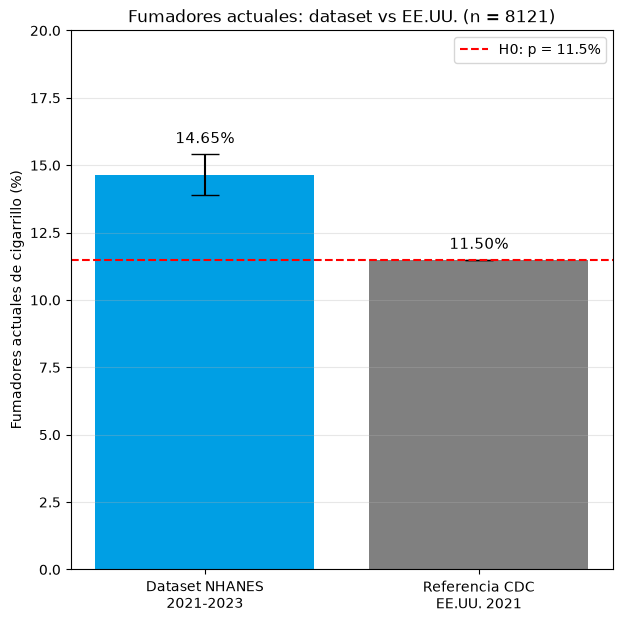

In [61]:
ic_bilateral = stats.ttest_1samp(fumador, popmean=p0).confidence_interval(confidence_level=0.95)
error_inferior = (proporcion_de_fumadores - ic_bilateral.low) * 100
error_superior = (ic_bilateral.high - proporcion_de_fumadores) * 100

print(f"IC 95% bilateral: [{ic_bilateral.low * 100:.2f}%, {ic_bilateral.high * 100:.2f}%]")

categorias = ["Dataset NHANES\n2021-2023", "Referencia CDC\nEE.UU. 2021"]
valores = [porcentaje_de_fumadores, p0 * 100]

plt.figure(figsize=(7, 7))
plt.bar(categorias, valores, color=["#009FE4", "gray"],
        yerr=[[error_inferior, 0], [error_superior, 0]], capsize=10)
plt.axhline(p0 * 100, color="red", linestyle="--", label=f"H0: p = {p0 * 100:.1f}%")

plt.text(0, porcentaje_de_fumadores + error_superior + 0.4, f"{porcentaje_de_fumadores:.2f}%", ha="center", fontsize=11)
plt.text(1, p0 * 100 + 0.4, f"{p0 * 100:.2f}%", ha="center", fontsize=11)

plt.ylabel("Fumadores actuales de cigarrillo (%)")
plt.title(f"Fumadores actuales: dataset vs EE.UU. (n = {n_total_observados})")
plt.ylim(0, 20)
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.show()

### Conclusión

El porcentaje de fumadores actuales de cigarrillo en los adultos del dataset es **14,65 %** (IC 95 %: 13,88 % – 15,42 %). Es mayor al 11,5 % que informa el CDC para EE.UU. en 2021.

El test t para una muestra da un p-valor muy menor a α = 0.05, por lo que **rechazamos H0**: el porcentaje de fumadores del dataset supera significativamente la cifra nacional. El gráfico lo confirma, porque el intervalo de confianza de la barra del dataset queda completo por encima de la línea del 11,5 %.

## Hipótesis 4a: la mayoría de los casos de CKF identificados corresponde a blancos no hispánicos

### Planteo de la hipótesis

**CKF** (*Chronic Kidney Failure*, falla renal crónica) corresponde a la última etapa de la enfermedad renal crónica: `Stage5` (en el archivo original, `Stage 5 (Kidney Failure)`), con eGFR menor a 15 mL/min/1,73 m².

"La mayoría" significa que los blancos no hispánicos representan **más del 50 %** de los casos de CKF identificados.

Los registros con `ckd_stage` igual a `Unknown` no tienen eGFR, así que no se puede saber si alguno está en la etapa 5. La hipótesis habla de casos **identificados**, por lo que analizamos solo los que tienen la etapa 5 asignada. Al filtrar por esa etapa, los `Unknown` quedan afuera automáticamente.

### Casos de CKF identificados

In [62]:
casos_ckf = data[data["ckd_stage"] == "Stage5"]
total_casos_ckf = len(casos_ckf)

print(f"Total de casos de CKF identificados: {total_casos_ckf}")
print(f"Casos sin etnia registrada: {casos_ckf['ethnicity'].isna().sum()}")
casos_ckf[["participant_id", "age", "gender", "ethnicity", "egfr"]]

Total de casos de CKF identificados: 11
Casos sin etnia registrada: 0


,participant_id,age,gender,ethnicity,egfr
433,130811,59,Male,Other Hispanic,10.67
2382,132760,60,Male,Non-Hispanic Black,6.46
2397,132775,46,Female,Mexican American,7.57
5669,136047,80,Male,Non-Hispanic White,12.58
6251,136629,50,Male,Non-Hispanic Asian,3.51
6454,136832,72,Male,Non-Hispanic White,9.62
8290,138668,49,Male,Other Hispanic,4.96
10198,140576,80,Female,Non-Hispanic White,7.53
11386,141764,62,Male,Non-Hispanic White,8.28
11480,141858,69,Male,Other/Multiracial,10.24


In [63]:
conteo_etnias = casos_ckf["ethnicity"].value_counts()
porcentaje_etnias = casos_ckf["ethnicity"].value_counts(normalize=True) * 100

tabla_etnias = pd.DataFrame({"Casos": conteo_etnias, "Porcentaje (%)": porcentaje_etnias.round(2)})
tabla_etnias

,Casos,Porcentaje (%)
ethnicity,,
Non-Hispanic White,4,36.36
Other Hispanic,2,18.18
Mexican American,2,18.18
Non-Hispanic Black,1,9.09
Non-Hispanic Asian,1,9.09
Other/Multiracial,1,9.09


### Gráfico: casos de CKF por etnia

Usamos un **gráfico de barras** con el porcentaje de casos de cada grupo étnico. La **línea roja punteada** marca el 50 %: para que la hipótesis se cumpla, la barra de los blancos no hispánicos (en azul) tendría que superarla.

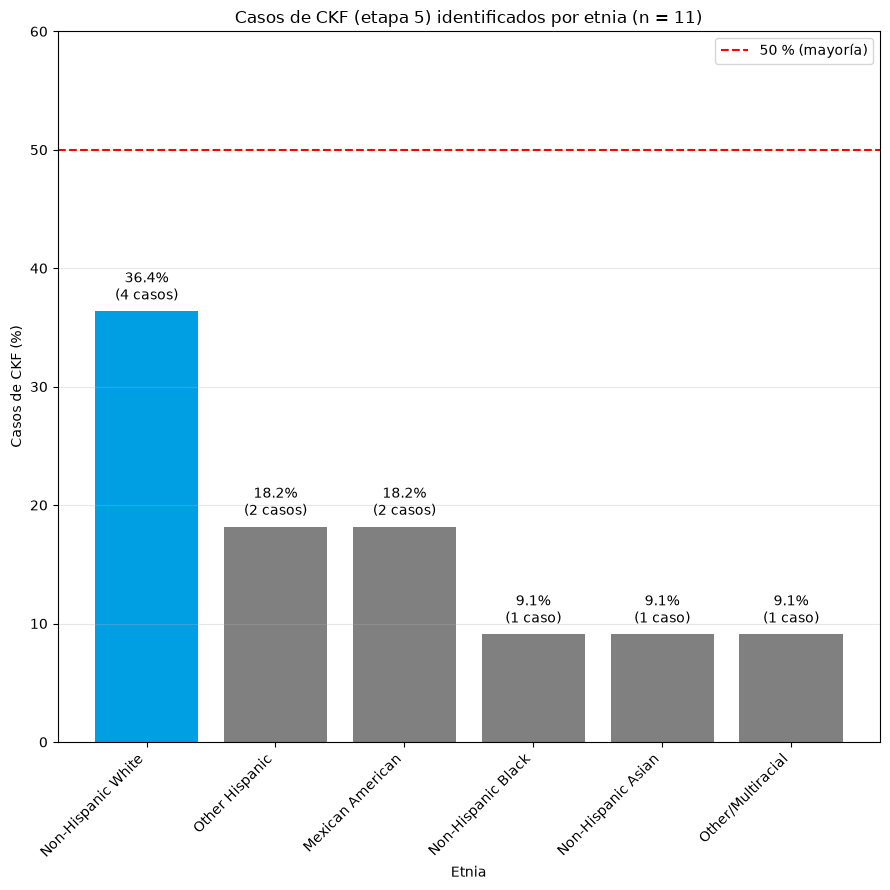

In [64]:
colores = ["#009FE4" if etnia == "Non-Hispanic White" else "gray" for etnia in porcentaje_etnias.index]

plt.figure(figsize=(9, 9))
plt.bar(porcentaje_etnias.index, porcentaje_etnias.values, color=colores)
plt.axhline(50, color="red", linestyle="--", label="50 % (mayoría)")

for i, etnia in enumerate(porcentaje_etnias.index):
    plt.text(i, porcentaje_etnias[etnia] + 1, f"{porcentaje_etnias[etnia]:.1f}%\n({conteo_etnias[etnia]} {'caso' if conteo_etnias[etnia] == 1 else 'casos'})", ha="center", fontsize=10)

plt.xlabel("Etnia")
plt.ylabel("Casos de CKF (%)")
plt.title(f"Casos de CKF (etapa 5) identificados por etnia (n = {total_casos_ckf})")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 60)
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Por qué no aplicamos un test de hipótesis

- **Test t para una muestra:** la aproximación a la normal por el teorema central del límite necesita muestras grandes (n ≥ 30). Con 11 casos no se cumple.
- **Chi-cuadrado:** necesita que las frecuencias esperadas sean de al menos 5 por categoría. Con 11 casos repartidos en 6 etnias, la frecuencia esperada es de 11 / 6 ≈ 1,8, así que tampoco se cumple. Además, este test responde si las etnias tienen la misma cantidad de casos, que es una pregunta distinta a "la mayoría son blancos no hispánicos".

### Conclusión

**La hipótesis no se cumple.** De los 11 casos de CKF identificados, 4 corresponden a blancos no hispánicos (36,4 %). Aunque es el grupo con más casos, no llega a ser la mayoría: los otros 7 casos (63,6 %) se reparten entre las demás etnias.

**Limitaciones:**
- Con solo 11 casos, los porcentajes son muy inestables: un caso más o menos en un grupo cambia su porcentaje en unos 9 puntos. El resultado describe a esta muestra, pero no permite sacar conclusiones firmes sobre la población.
- A 5607 personas (`Unknown`) no se les midió la creatinina, así que no se sabe si alguna tiene CKF.

## Análisis de la hipótesis bivariada: existen diferencias en la capacidad de filtrado entre hombres y mujeres

### Planteo de la hipótesis

La capacidad de filtrado de los riñones se mide con la tasa de filtrado glomerular estimada (`egfr`, en mL/min/1,73 m²). Comparamos esta variable entre dos grupos independientes definidos por `gender`: hombres y mujeres.

- **H0:** no existen diferencias en la capacidad de filtrado (`egfr`) entre hombres y mujeres.
- **H1:** existen diferencias en la capacidad de filtrado (`egfr`) entre hombres y mujeres.
- **Nivel de significancia:** α = 0.05

### Población analizada

Tomamos las personas que tienen `egfr` calculado (las de etapa `Unknown` no lo tienen) y que son **mayores de 18 años**. Excluimos a los menores porque la ecuación CKD-EPI 2021, con la que se calculó el eGFR, está pensada para adultos, y la metadata advierte que el eGFR debe interpretarse con cautela en los extremos de edad.

A los adolescentes podríamos compararlos por separado y así tener una comparación de hombres y mujeres en su adolescencia y, por otro lado, la comparación en su adultez. Como mencionamos antes, el cálculo está pensado para los adultos, por lo que descartamos el análisis sobre los adolescentes.

Después separamos la variable `egfr` en los dos grupos a comparar.

In [65]:
adultos_con_egfr = data[(data["egfr"].notna()) & (data["age"] >= 18)]

egfr_hombres = adultos_con_egfr[adultos_con_egfr["gender"] == "Male"]["egfr"]
egfr_mujeres = adultos_con_egfr[adultos_con_egfr["gender"] == "Female"]["egfr"]

print(f"Adultos con eGFR: {len(adultos_con_egfr)}")
print(f"Hombres: {len(egfr_hombres)}")
print(f"Mujeres: {len(egfr_mujeres)}")

adultos_con_egfr.groupby("gender")["egfr"].describe().round(2)

Adultos con eGFR: 5658
Hombres: 2568
Mujeres: 3090


,count,mean,std,min,25%,50%,75%,max
gender,,,,,,,,
Female,3090.0,93.01,22.02,7.53,78.53,94.73,108.76,140.17
Male,2568.0,91.33,21.61,3.51,78.20,93.56,105.72,148.98


### Análisis gráfico de la hipótesis

Graficamos un **boxplot** de `egfr` para cada sexo. La línea del medio de cada caja es la mediana, y el *notch* (la muesca alrededor de la mediana) es un intervalo de confianza aproximado de la mediana: si los notches de los dos grupos no se superponen, es un indicio de que las medianas son distintas.

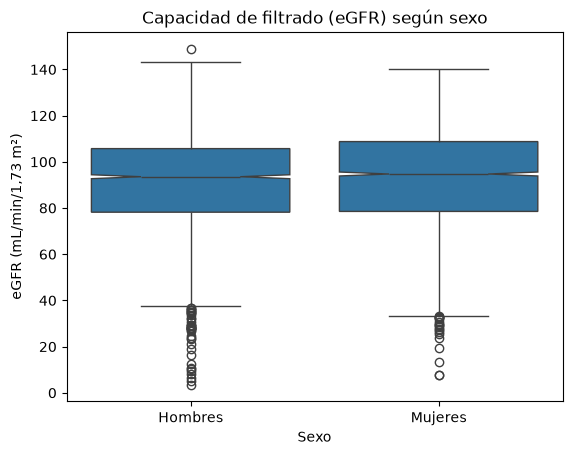

In [66]:
import seaborn as sns

sns.boxplot(x="gender", y="egfr", data=adultos_con_egfr, order=["Male", "Female"], notch=True)
plt.title("Capacidad de filtrado (eGFR) según sexo")
plt.xlabel("Sexo")
plt.xticks(ticks=[0, 1], labels=["Hombres", "Mujeres"])
plt.ylabel("eGFR (mL/min/1,73 m²)")
plt.show()

Las dos cajas son muy parecidas: la mediana de las mujeres (94,7) es apenas mayor que la de los hombres (93,6), y los notches casi se superponen. A simple vista la diferencia es muy chica, así que verificaremos los supuestos de normalidad y homocedasticidad para elegir el test correcto y saber si es significativa. También se ven muchos outliers en la parte de abajo (personas con filtrado muy bajo); esto es un indicio de que la distribución no es simétrica.

### Supuesto 1: normalidad
Evaluamos la normalidad con el **test de Shapiro-Wilk**, cuya hipótesis nula es que los datos son normales: si el p-valor es menor a α, se rechaza la normalidad.

In [67]:
from scipy.stats import shapiro

alpha = 0.05

stat, p = shapiro(egfr_hombres)
print(f"Test de Shapiro-Wilk para hombres: Estadístico={stat:.3f}, p-valor={p:.3e}")

stat, p = shapiro(egfr_mujeres)
print(f"Test de Shapiro-Wilk para mujeres: Estadístico={stat:.3f}, p-valor={p:.3e}")

Test de Shapiro-Wilk para hombres: Estadístico=0.983, p-valor=6.648e-17
Test de Shapiro-Wilk para mujeres: Estadístico=0.987, p-valor=4.541e-16


En los dos grupos el p-valor es menor a 0.05, así que **rechazamos la normalidad**.

Lo complementamos con un **QQ plot** por grupo. El eje X tiene los cuantiles de una distribución normal teórica y el eje Y los cuantiles de los datos. Si los puntos siguen la línea roja, los datos son normales; si se alejan, no lo son.

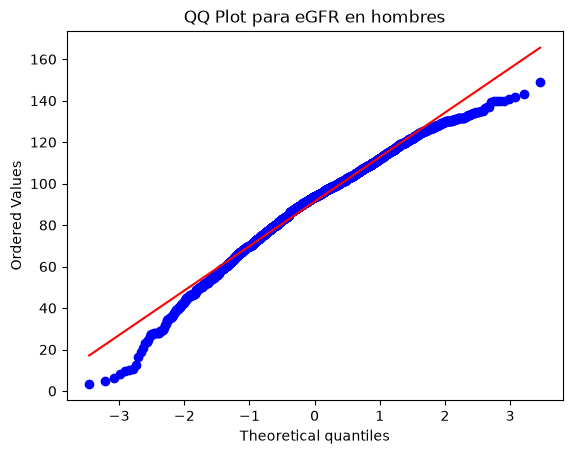

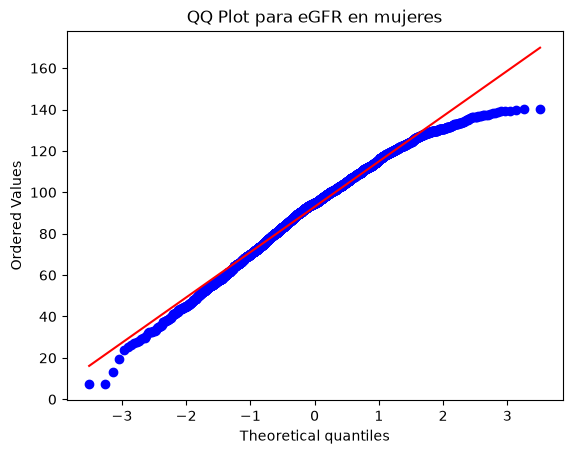

In [68]:
stats.probplot(egfr_hombres, dist="norm", plot=plt)
plt.title("QQ Plot para eGFR en hombres")
plt.show()

stats.probplot(egfr_mujeres, dist="norm", plot=plt)
plt.title("QQ Plot para eGFR en mujeres")
plt.show()

En los dos QQ plots los puntos se apartan de la línea en los extremos: abajo a la izquierda caen muy por debajo (personas con filtrado muy bajo, una cola larga hacia valores chicos) y arriba a la derecha quedan por debajo de la línea. Esto coincide con el resultado de Shapiro-Wilk: **eGFR no se distribuye normal en ningún grupo**.

### Supuesto 2: homocedasticidad

Evaluamos si las varianzas de `egfr` son iguales en los dos grupos con el **test de Levene**, que elegimos porque es más robusto que el test F de Fisher cuando los datos no son normales. Su hipótesis nula es que las varianzas son iguales.

In [69]:
stat, p = stats.levene(egfr_hombres, egfr_mujeres)
print(f"Test de Levene para eGFR: Estadístico={stat:.3f}, p-valor={p:.3f}")

if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("Las varianzas de eGFR son iguales entre hombres y mujeres.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Las varianzas de eGFR son diferentes entre hombres y mujeres.")

Test de Levene para eGFR: Estadístico=4.955, p-valor=0.026
Se rechaza la hipótesis nula.
Las varianzas de eGFR son diferentes entre hombres y mujeres.


El p-valor es menor a 0.05, así que **no hay homocedasticidad**.

### Elección del test

Como no se cumple ninguno de los dos supuestos, usamos el **test de Kruskal-Wallis**, que no necesita normalidad ni varianzas iguales. Trabaja con los **rangos** de los datos (su posición al ordenarlos de menor a mayor) en lugar de con los valores, por eso también es robusto a los outliers que se vieron en el boxplot. Su hipótesis nula es que no hay diferencias entre los grupos.

In [70]:
stat, p = stats.kruskal(egfr_hombres, egfr_mujeres)
print(f"Test de Kruskal-Wallis para eGFR: Estadístico={stat:.3f}, p-valor={p:.4f}")

if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en la capacidad de filtrado entre hombres y mujeres.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en la capacidad de filtrado entre hombres y mujeres.")

print(f"Mediana de eGFR en hombres: {egfr_hombres.median():.2f}")
print(f"Mediana de eGFR en mujeres: {egfr_mujeres.median():.2f}")

Test de Kruskal-Wallis para eGFR: Estadístico=7.992, p-valor=0.0047
Se rechaza la hipótesis nula.
Existe una diferencia significativa en la capacidad de filtrado entre hombres y mujeres.
Mediana de eGFR en hombres: 93.56
Mediana de eGFR en mujeres: 94.73


### Conclusión

**Rechazamos H0: existen diferencias significativas en la capacidad de filtrado entre hombres y mujeres** (Kruskal-Wallis, p ≈ 0,005). Las mujeres tienen una mediana de eGFR levemente mayor (94,7) que la de los hombres (93,6).

Sin embargo, la diferencia es de solo 1,2 mL/min/1,73 m², muy chica desde el punto de vista clínico: no cambia la etapa renal de nadie (los cortes entre etapas están separados por 15 a 30 unidades). Con más de 5600 personas, el test es capaz de detectar diferencias muy pequeñas, por lo que el resultado es **estadísticamente significativo pero de poca relevancia práctica**, como también se veía en el boxplot.

La ecuación CKD-EPI 2021 usa el sexo para calcular el eGFR, para corregir que los hombres tienen más masa muscular y, por eso, más creatinina en sangre. La comparación muestra la diferencia que queda después de ese ajuste.

## Hipótesis 4b: la presión arterial es un factor de riesgo del CKF

### Planteo de la hipótesis

La presión arterial se mide con dos valores: la **sistólica** (`bp_systolic`, la presión máxima, cuando el corazón se contrae) y la **diastólica** (`bp_diastolic`, la presión mínima, entre latidos). Las dos forman parte de la presión arterial, así que las analizamos **por separado**, comparando cada una entre las personas con CKF y sin CKF. Cada comparación relaciona una variable con la presencia de CKF, por lo que la hipótesis es **bivariada**.

**Presión sistólica:**
- **H0:** no existen diferencias en la presión sistólica entre personas con CKF y sin CKF.
- **H1:** existen diferencias en la presión sistólica entre personas con CKF y sin CKF.

**Presión diastólica:**
- **H0:** no existen diferencias en la presión diastólica entre personas con CKF y sin CKF.
- **H1:** existen diferencias en la presión diastólica entre personas con CKF y sin CKF.

**Nivel de significancia:** α = 0.05

### Población y grupos

Trabajamos con los **adultos evaluados**: mayores de 18 años con eGFR calculado (los `Unknown` quedan afuera, porque no se sabe si tienen CKF) y con la presión arterial medida.

- **Grupo CKF:** personas en `Stage5`.
- **Grupo sin CKF:** el resto de los adultos evaluados (`No CKD` y `Stage1` a `Stage4`).

In [78]:
adultos_evaluados = data[(data["egfr"].notna()) & (data["age"] >= 18)].copy()
adultos_evaluados = adultos_evaluados.dropna(subset=["bp_systolic", "bp_diastolic"])

adultos_evaluados["grupo_ckf"] = ["CKF" if etapa == "Stage5" else "Sin CKF" for etapa in adultos_evaluados["ckd_stage"]]

con_ckf = adultos_evaluados[adultos_evaluados["grupo_ckf"] == "CKF"]
sin_ckf = adultos_evaluados[adultos_evaluados["grupo_ckf"] == "Sin CKF"]

print(f"Adultos evaluados con presión medida: {len(adultos_evaluados)}")
print(f"Con CKF: {len(con_ckf)}")
print(f"Sin CKF: {len(sin_ckf)}")


Adultos evaluados con presión medida: 5484
Con CKF: 11
Sin CKF: 5473


Como el grupo con CKF tiene solo 11 personas, mostramos sus valores uno por uno:

In [72]:
con_ckf[["age", "gender", "bp_systolic", "bp_diastolic", "egfr"]]

,age,gender,bp_systolic,bp_diastolic,egfr
433,59,Male,131,70,10.67
2382,60,Male,232,116,6.46
2397,46,Female,80,45,7.57
5669,80,Male,150,64,12.58
6251,50,Male,139,71,3.51
6454,72,Male,116,50,9.62
8290,49,Male,178,94,4.96
10198,80,Female,197,62,7.53
11386,62,Male,157,65,8.28
11480,69,Male,139,81,10.24


### Análisis gráfico de la hipótesis

Graficamos un **boxplot** de cada presión para los dos grupos. Como el grupo CKF tiene pocos casos, encima de su caja dibujamos cada persona como un punto rojo con `sns.stripplot`, que grafica cada observación individual. Así podemos ver si la caja está influida por algún valor extremo.

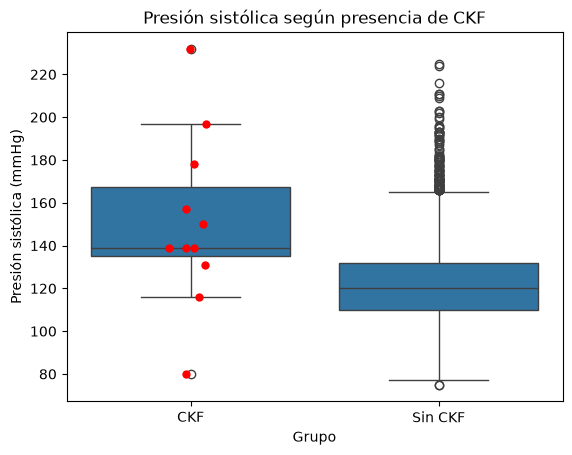

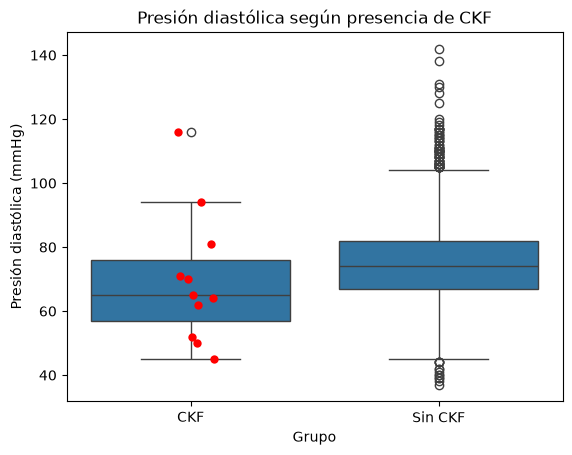

In [73]:
import seaborn as sns

orden_grupos = ["CKF", "Sin CKF"]

sns.boxplot(x="grupo_ckf", y="bp_systolic", data=adultos_evaluados, order=orden_grupos)
sns.stripplot(x="grupo_ckf", y="bp_systolic", data=con_ckf, order=orden_grupos, color="red", size=6)
plt.title("Presión sistólica según presencia de CKF")
plt.xlabel("Grupo")
plt.ylabel("Presión sistólica (mmHg)")
plt.show()

sns.boxplot(x="grupo_ckf", y="bp_diastolic", data=adultos_evaluados, order=orden_grupos)
sns.stripplot(x="grupo_ckf", y="bp_diastolic", data=con_ckf, order=orden_grupos, color="red", size=6)
plt.title("Presión diastólica según presencia de CKF")
plt.xlabel("Grupo")
plt.ylabel("Presión diastólica (mmHg)")
plt.show()

En la **sistólica**, la caja del grupo CKF está claramente más arriba: su mediana es 139 mmHg contra 120 del grupo sin CKF, y la mayoría de sus puntos están por encima de la caja del otro grupo. En la **diastólica** pasa lo contrario: la mediana del grupo CKF (65 mmHg) es menor que la del grupo sin CKF (74 mmHg), con mucha dispersión. En los dos gráficos se ven casos extremos dentro del grupo CKF (por ejemplo, una persona con 232/116 y otra con 80/45), que con tan pocos datos pesan mucho.

### Supuesto 1: normalidad

Evaluamos la normalidad con el **test de Shapiro-Wilk** para cada grupo y cada presión (H0: los datos son normales).

- **Grupo CKF:** con solo 11 datos, el test tiene muy poca potencia: que no se rechace no prueba que sean normales, por eso es importante mirar también el QQ plot.

In [74]:
from scipy.stats import shapiro

alpha = 0.05

stat, p = shapiro(con_ckf["bp_systolic"])
print(f"Test de Shapiro-Wilk para presión sistólica con CKF: Estadístico={stat:.3f}, p-valor={p:.3f}")

stat, p = shapiro(sin_ckf["bp_systolic"])
print(f"Test de Shapiro-Wilk para presión sistólica sin CKF: Estadístico={stat:.3f}, p-valor={p:.3e}")

stat, p = shapiro(con_ckf["bp_diastolic"])
print(f"Test de Shapiro-Wilk para presión diastólica con CKF: Estadístico={stat:.3f}, p-valor={p:.3f}")

stat, p = shapiro(sin_ckf["bp_diastolic"])
print(f"Test de Shapiro-Wilk para presión diastólica sin CKF: Estadístico={stat:.3f}, p-valor={p:.3e}")

Test de Shapiro-Wilk para presión sistólica con CKF: Estadístico=0.959, p-valor=0.759
Test de Shapiro-Wilk para presión sistólica sin CKF: Estadístico=0.960, p-valor=2.117e-36
Test de Shapiro-Wilk para presión diastólica con CKF: Estadístico=0.914, p-valor=0.273
Test de Shapiro-Wilk para presión diastólica sin CKF: Estadístico=0.983, p-valor=4.345e-25


/home/franco/Fundamentos/TPE/lib64/python3.14/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5473.
  res = hypotest_fun_out(*samples, **kwds)
/home/franco/Fundamentos/TPE/lib64/python3.14/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5473.
  res = hypotest_fun_out(*samples, **kwds)


En el grupo **sin CKF** rechazamos la normalidad en las dos presiones. En el grupo **CKF** no la rechazamos, pero por lo explicado arriba eso no alcanza para asumirla. Como basta con que un grupo no sea normal para no poder usar el test t, **no se cumple el supuesto de normalidad**.

Complementamos con los QQ plots de cada grupo:

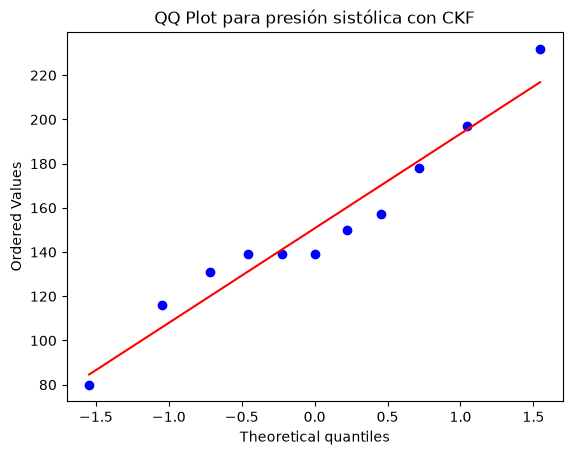

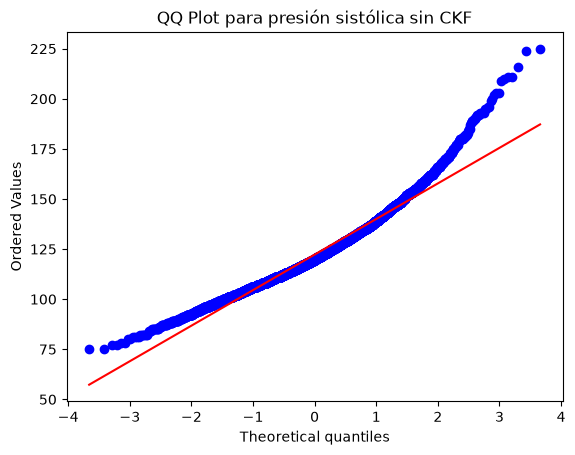

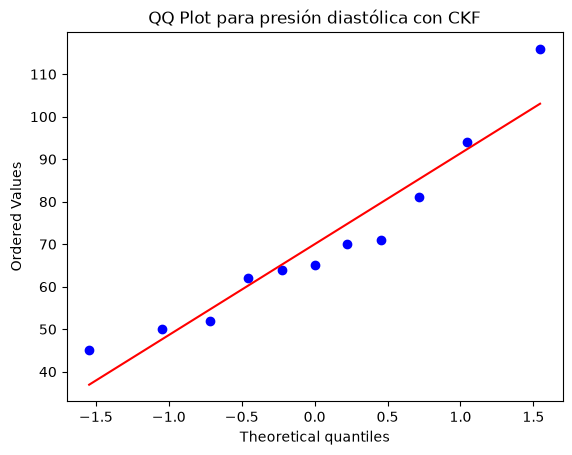

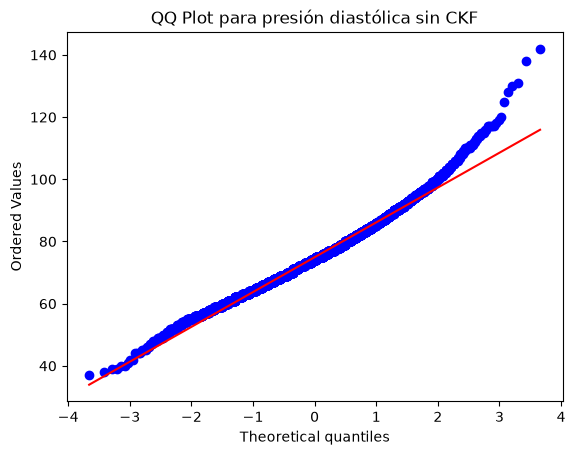

In [75]:
stats.probplot(con_ckf["bp_systolic"], dist="norm", plot=plt)
plt.title("QQ Plot para presión sistólica con CKF")
plt.show()

stats.probplot(sin_ckf["bp_systolic"], dist="norm", plot=plt)
plt.title("QQ Plot para presión sistólica sin CKF")
plt.show()

stats.probplot(con_ckf["bp_diastolic"], dist="norm", plot=plt)
plt.title("QQ Plot para presión diastólica con CKF")
plt.show()

stats.probplot(sin_ckf["bp_diastolic"], dist="norm", plot=plt)
plt.title("QQ Plot para presión diastólica sin CKF")
plt.show()

En el grupo **sin CKF**, los puntos se curvan por encima de la línea en el extremo derecho: hay una cola larga hacia valores altos de presión (asimetría a derecha), lo que confirma que no es normal. En el grupo **CKF** los 11 puntos están cerca de la línea, salvo los casos extremos en las puntas, pero con tan pocos puntos el gráfico no permite asegurar la normalidad.

### Supuesto 2: homocedasticidad

Evaluamos la homocedasticidad con el **test de Levene** (H0: las varianzas son iguales) para cada presión.

In [76]:
stat, p = stats.levene(con_ckf["bp_systolic"], sin_ckf["bp_systolic"])
print(f"Test de Levene para presión sistólica: Estadístico={stat:.3f}, p-valor={p:.3f}")

stat, p = stats.levene(con_ckf["bp_diastolic"], sin_ckf["bp_diastolic"])
print(f"Test de Levene para presión diastólica: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Levene para presión sistólica: Estadístico=15.547, p-valor=0.000
Test de Levene para presión diastólica: Estadístico=6.848, p-valor=0.009


En las dos presiones el p-valor es menor a 0.05, así que **no hay homocedasticidad**: la presión varía mucho más en el grupo CKF que en el grupo sin CKF, como se veía en los boxplots.

### Elección del test

No se cumple ninguno de los dos supuestos, así que usamos el **test de Kruskal-Wallis** para cada presión. Como trabaja con los rangos de los datos y no con sus valores, no necesita normalidad, es robusto a los valores extremos y sirve para grupos chicos como el de CKF.

In [77]:
stat, p = stats.kruskal(con_ckf["bp_systolic"], sin_ckf["bp_systolic"])
print(f"Test de Kruskal-Wallis para presión sistólica: Estadístico={stat:.3f}, p-valor={p:.4f}")
print(f"Mediana con CKF: {con_ckf['bp_systolic'].median():.1f} mmHg | Mediana sin CKF: {sin_ckf['bp_systolic'].median():.1f} mmHg")

if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en la presión sistólica entre personas con y sin CKF.\n")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en la presión sistólica entre personas con y sin CKF.\n")

stat, p = stats.kruskal(con_ckf["bp_diastolic"], sin_ckf["bp_diastolic"])
print(f"Test de Kruskal-Wallis para presión diastólica: Estadístico={stat:.3f}, p-valor={p:.4f}")
print(f"Mediana con CKF: {con_ckf['bp_diastolic'].median():.1f} mmHg | Mediana sin CKF: {sin_ckf['bp_diastolic'].median():.1f} mmHg")

if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en la presión diastólica entre personas con y sin CKF.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en la presión diastólica entre personas con y sin CKF.")

Test de Kruskal-Wallis para presión sistólica: Estadístico=10.044, p-valor=0.0015
Mediana con CKF: 139.0 mmHg | Mediana sin CKF: 120.0 mmHg
Se rechaza la hipótesis nula.
Existe una diferencia significativa en la presión sistólica entre personas con y sin CKF.

Test de Kruskal-Wallis para presión diastólica: Estadístico=2.887, p-valor=0.0893
Mediana con CKF: 65.0 mmHg | Mediana sin CKF: 74.0 mmHg
No hay suficiente evidencia para rechazar la hipótesis nula.
No hay una diferencia significativa en la presión diastólica entre personas con y sin CKF.


### Conclusión

**La hipótesis se confirma parcialmente.**

- **Presión sistólica:** rechazamos H0 (p ≈ 0,002). Las personas con CKF tienen la presión sistólica significativamente más alta (mediana de 139 mmHg contra 120 mmHg). Además, 9 de los 11 casos tienen una sistólica de 130 mmHg o más, valor a partir del cual se considera hipertensión.
- **Presión diastólica:** no rechazamos H0 (p ≈ 0,09). No hay evidencia de diferencias; de hecho, la mediana del grupo CKF es algo menor (65 contra 74 mmHg).

Que la sistólica esté alta y la diastólica baja podría deberse a que en el grupo con CKF la mediana de edad es de 62 años, contra 56 años en el grupo sin CKF: con la edad y la enfermedad renal, las arterias se vuelven más rígidas, lo que provoca que la presión sistólica suba y la diastólica baje.

**Limitaciones:**
- Con solo 11 casos de CKF, el análisis tiene poca potencia: que la diastólica no dé significativa no prueba que no haya diferencia, y uno o dos casos extremos pueden mover mucho el resultado.
- El resultado muestra una **asociación**, no que la presión cause el CKF. La relación puede ir en los dos sentidos: la hipertensión daña el riñón y la enfermedad renal también eleva la presión.
- La edad influye tanto en la presión como en la función renal, así que parte de la diferencia puede deberse a la edad. Este efecto lo podemos controlar en un análisis multivariado, como el de la hipótesis 4c.
- El dataset no informa si las personas toman medicación para la presión o están en diálisis, dos tratamientos habituales en el CKF que modifican la presión medida el día del examen.